In [41]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

In [42]:
columns = [
    'id', 'diagnosis',
    'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
    'smoothness_mean', 'compactness_mean', 'concavity_mean',
    'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean',
    'radius_se', 'texture_se', 'perimeter_se', 'area_se',
    'smoothness_se', 'compactness_se', 'concavity_se',
    'concave_points_se', 'symmetry_se', 'fractal_dimension_se',
    'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst',
    'smoothness_worst', 'compactness_worst', 'concavity_worst',
    'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst'
]

df = pd.read_csv("data - data.csv", header=None, names=columns)
df = df.drop(columns="id").drop_duplicates()

df["diagnosis"] = df["diagnosis"].astype(str).str.strip().map({"B": 0, "M": 1})
df = df.dropna(subset=["diagnosis"])

X = df.drop(columns="diagnosis")
y = df["diagnosis"].astype(int)

X = X.fillna(X.median())

print("Missing feature values:", X.isnull().sum().sum())
print("Features:", X.shape)
print("Target:", y.shape)

Missing feature values: 0
Features: (569, 30)
Target: (569,)


In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (455, 30)
Testing data: (114, 30)


In [44]:
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

In [45]:
svm_cv = cross_val_score(
    SVC(), X_train_scaled, y_train, cv=kfold, scoring="accuracy"
)

rf_cv = cross_val_score(
    RandomForestClassifier(random_state=42),
    X_train, y_train, cv=kfold, scoring="accuracy"
)

ada_cv = cross_val_score(
    AdaBoostClassifier(random_state=42),
    X_train, y_train, cv=kfold, scoring="accuracy"
)

print("SVM Cross Validation Scores:", svm_cv)
print("SVM Mean CV Accuracy:", svm_cv.mean())

print("\nRandom Forest Cross Validation Scores:", rf_cv)
print("Random Forest Mean CV Accuracy:", rf_cv.mean())

print("\nAdaBoost Cross Validation Scores:", ada_cv)
print("AdaBoost Mean CV Accuracy:", ada_cv.mean())

SVM Cross Validation Scores: [0.95604396 0.97802198 0.97802198 0.98901099 0.96703297]
SVM Mean CV Accuracy: 0.9736263736263735

Random Forest Cross Validation Scores: [0.95604396 0.96703297 0.97802198 0.94505495 0.92307692]
Random Forest Mean CV Accuracy: 0.9538461538461538

AdaBoost Cross Validation Scores: [0.97802198 0.97802198 0.97802198 0.95604396 0.92307692]
AdaBoost Mean CV Accuracy: 0.9626373626373625


SVM Before Tuning
Accuracy: 0.9824561403508771
Precision: 1.0
Recall: 0.9534883720930233
F1 Score: 0.9761904761904762


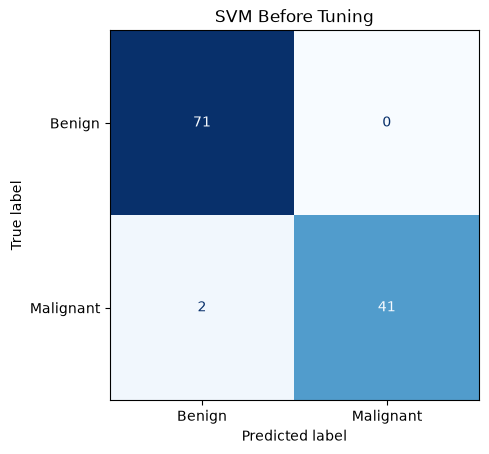

In [46]:
results = []

svm = SVC()
svm.fit(X_train_scaled, y_train)
svm_pred = svm.predict(X_test_scaled)

results.append({
    "Model": "SVM Before Tuning",
    "Accuracy": accuracy_score(y_test, svm_pred),
    "Precision": precision_score(y_test, svm_pred, zero_division=0),
    "Recall": recall_score(y_test, svm_pred, zero_division=0),
    "F1 Score": f1_score(y_test, svm_pred, zero_division=0)
})

print("SVM Before Tuning")
print("Accuracy:", accuracy_score(y_test, svm_pred))
print("Precision:", precision_score(y_test, svm_pred))
print("Recall:", recall_score(y_test, svm_pred))
print("F1 Score:", f1_score(y_test, svm_pred))

cm = confusion_matrix(y_test, svm_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
).plot(cmap="Blues", colorbar=False)

plt.title("SVM Before Tuning")
plt.show()

Best SVM Parameters: {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}
Best CV F1 Score: 0.977092164727619
SVM After Tuning
Accuracy: 0.9824561403508771
Precision: 1.0
Recall: 0.9534883720930233
F1 Score: 0.9761904761904762


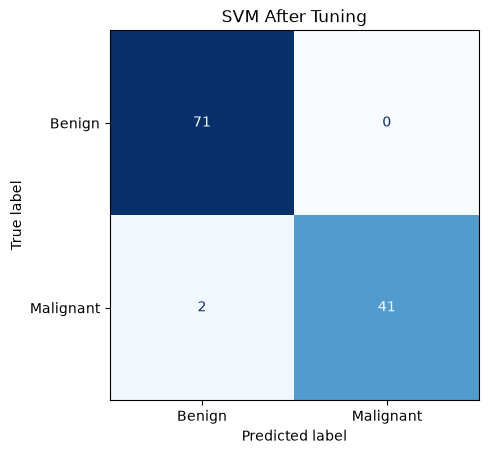

In [47]:
svm_params = {
    "C": [0.1, 1, 10],
    "kernel": ["linear", "rbf"],
    "gamma": ["scale", 0.01, 0.1]
}

svm_grid = GridSearchCV(
    SVC(), svm_params, cv=kfold, scoring="f1", n_jobs=-1
)

svm_grid.fit(X_train_scaled, y_train)

print("Best SVM Parameters:", svm_grid.best_params_)
print("Best CV F1 Score:", svm_grid.best_score_)

best_svm = svm_grid.best_estimator_
svm_tuned_pred = best_svm.predict(X_test_scaled)

results.append({
    "Model": "SVM Tuned",
    "Accuracy": accuracy_score(y_test, svm_tuned_pred),
    "Precision": precision_score(y_test, svm_tuned_pred, zero_division=0),
    "Recall": recall_score(y_test, svm_tuned_pred, zero_division=0),
    "F1 Score": f1_score(y_test, svm_tuned_pred, zero_division=0)
})

print("SVM After Tuning")
print("Accuracy:", accuracy_score(y_test, svm_tuned_pred))
print("Precision:", precision_score(y_test, svm_tuned_pred))
print("Recall:", recall_score(y_test, svm_tuned_pred))
print("F1 Score:", f1_score(y_test, svm_tuned_pred))

cm = confusion_matrix(y_test, svm_tuned_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
).plot(cmap="Blues", colorbar=False)

plt.title("SVM After Tuning")
plt.show()

Random Forest Before Tuning
Accuracy: 0.9649122807017544
Precision: 0.975609756097561
Recall: 0.9302325581395349
F1 Score: 0.9523809523809523


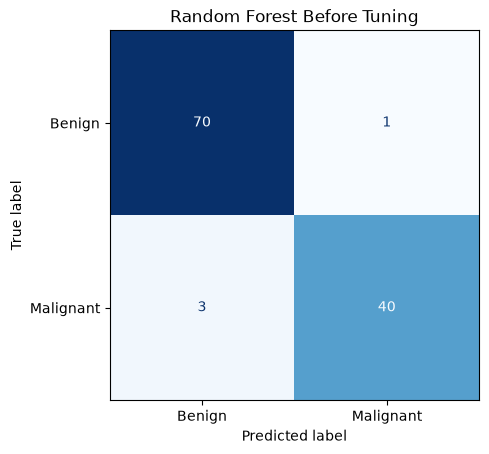

In [48]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

results.append({
    "Model": "Random Forest Before Tuning",
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(y_test, rf_pred, zero_division=0),
    "Recall": recall_score(y_test, rf_pred, zero_division=0),
    "F1 Score": f1_score(y_test, rf_pred, zero_division=0)
})

print("Random Forest Before Tuning")
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))

cm = confusion_matrix(y_test, rf_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
).plot(cmap="Blues", colorbar=False)

plt.title("Random Forest Before Tuning")
plt.show()

Best Random Forest Parameters: {'max_depth': None, 'n_estimators': 100}
Best CV F1 Score: 0.9335077644284487
Random Forest After Tuning
Accuracy: 0.9649122807017544
Precision: 0.975609756097561
Recall: 0.9302325581395349
F1 Score: 0.9523809523809523


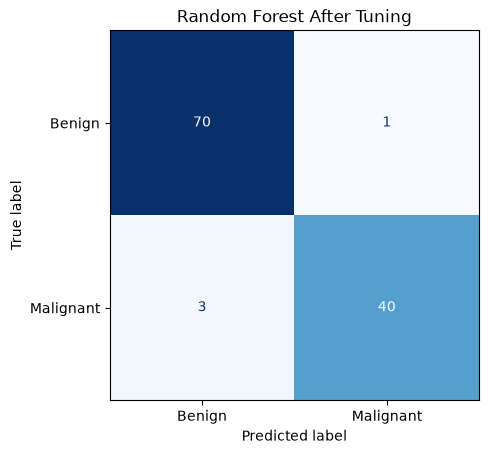

In [49]:
rf_params = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_params,
    cv=kfold,
    scoring="f1",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest Parameters:", rf_grid.best_params_)
print("Best CV F1 Score:", rf_grid.best_score_)

best_rf = rf_grid.best_estimator_
rf_tuned_pred = best_rf.predict(X_test)

results.append({
    "Model": "Random Forest Tuned",
    "Accuracy": accuracy_score(y_test, rf_tuned_pred),
    "Precision": precision_score(y_test, rf_tuned_pred, zero_division=0),
    "Recall": recall_score(y_test, rf_tuned_pred, zero_division=0),
    "F1 Score": f1_score(y_test, rf_tuned_pred, zero_division=0)
})

print("Random Forest After Tuning")
print("Accuracy:", accuracy_score(y_test, rf_tuned_pred))
print("Precision:", precision_score(y_test, rf_tuned_pred))
print("Recall:", recall_score(y_test, rf_tuned_pred))
print("F1 Score:", f1_score(y_test, rf_tuned_pred))

cm = confusion_matrix(y_test, rf_tuned_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
).plot(cmap="Blues", colorbar=False)

plt.title("Random Forest After Tuning")
plt.show()

AdaBoost Before Tuning
Accuracy: 0.9649122807017544
Precision: 0.975609756097561
Recall: 0.9302325581395349
F1 Score: 0.9523809523809523


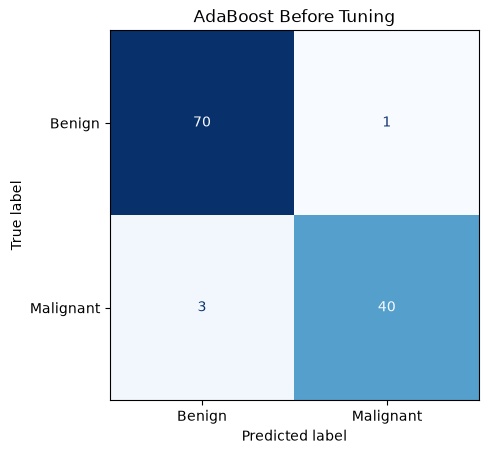

In [50]:
ada = AdaBoostClassifier(random_state=42)
ada.fit(X_train, y_train)
ada_pred = ada.predict(X_test)

results.append({
    "Model": "AdaBoost Before Tuning",
    "Accuracy": accuracy_score(y_test, ada_pred),
    "Precision": precision_score(y_test, ada_pred, zero_division=0),
    "Recall": recall_score(y_test, ada_pred, zero_division=0),
    "F1 Score": f1_score(y_test, ada_pred, zero_division=0)
})

print("AdaBoost Before Tuning")
print("Accuracy:", accuracy_score(y_test, ada_pred))
print("Precision:", precision_score(y_test, ada_pred))
print("Recall:", recall_score(y_test, ada_pred))
print("F1 Score:", f1_score(y_test, ada_pred))

cm = confusion_matrix(y_test, ada_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
).plot(cmap="Blues", colorbar=False)

plt.title("AdaBoost Before Tuning")
plt.show()

Best AdaBoost Parameters: {'estimator': DecisionTreeClassifier(max_depth=2, random_state=42), 'learning_rate': 0.5, 'n_estimators': 100}
Best CV F1 Score: 0.9534234340521035
AdaBoost After Tuning
Accuracy: 0.9649122807017544
Precision: 0.975609756097561
Recall: 0.9302325581395349
F1 Score: 0.9523809523809523


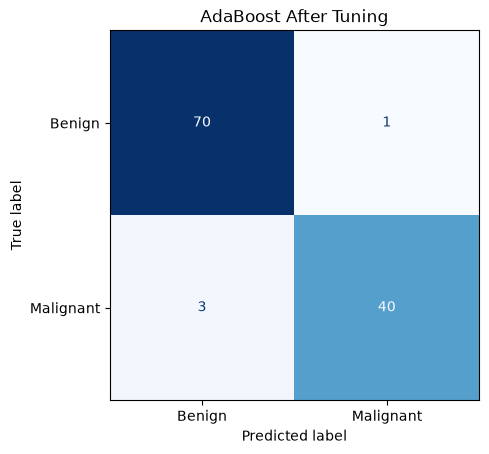

In [51]:
ada_params = {
    "n_estimators": [50, 100, 200],
    "learning_rate": [0.1, 0.5, 1.0],
    "estimator": [
        DecisionTreeClassifier(max_depth=1, random_state=42),
        DecisionTreeClassifier(max_depth=2, random_state=42)
    ]
}

ada_grid = GridSearchCV(
    AdaBoostClassifier(random_state=42),
    ada_params,
    cv=kfold,
    scoring="f1",
    n_jobs=-1
)

ada_grid.fit(X_train, y_train)

print("Best AdaBoost Parameters:", ada_grid.best_params_)
print("Best CV F1 Score:", ada_grid.best_score_)

best_ada = ada_grid.best_estimator_
ada_tuned_pred = best_ada.predict(X_test)

results.append({
    "Model": "AdaBoost Tuned",
    "Accuracy": accuracy_score(y_test, ada_tuned_pred),
    "Precision": precision_score(y_test, ada_tuned_pred, zero_division=0),
    "Recall": recall_score(y_test, ada_tuned_pred, zero_division=0),
    "F1 Score": f1_score(y_test, ada_tuned_pred, zero_division=0)
})

print("AdaBoost After Tuning")
print("Accuracy:", accuracy_score(y_test, ada_tuned_pred))
print("Precision:", precision_score(y_test, ada_tuned_pred))
print("Recall:", recall_score(y_test, ada_tuned_pred))
print("F1 Score:", f1_score(y_test, ada_tuned_pred))

cm = confusion_matrix(y_test, ada_tuned_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
).plot(cmap="Blues", colorbar=False)

plt.title("AdaBoost After Tuning")
plt.show()

In [52]:
svm_tuned_cv = cross_val_score(
    best_svm, X_train_scaled, y_train, cv=kfold, scoring="accuracy"
)

rf_tuned_cv = cross_val_score(
    best_rf, X_train, y_train, cv=kfold, scoring="accuracy"
)

ada_tuned_cv = cross_val_score(
    best_ada, X_train, y_train, cv=kfold, scoring="accuracy"
)

print("\nSVM Tuned Mean CV Accuracy:", svm_tuned_cv.mean())
print("Random Forest Tuned Mean CV Accuracy:", rf_tuned_cv.mean())
print("AdaBoost Tuned Mean CV Accuracy:", ada_tuned_cv.mean())


SVM Tuned Mean CV Accuracy: 0.9824175824175825
Random Forest Tuned Mean CV Accuracy: 0.9538461538461538
AdaBoost Tuned Mean CV Accuracy: 0.9670329670329672


In [53]:
comparison = pd.DataFrame(results)
display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,SVM Before Tuning,0.9825,1.0000,0.9535,0.9762
1,SVM Tuned,0.9825,1.0000,0.9535,0.9762
2,Random Forest Before Tuning,0.9649,0.9756,0.9302,0.9524
3,Random Forest Tuned,0.9649,0.9756,0.9302,0.9524
4,AdaBoost Before Tuning,0.9649,0.9756,0.9302,0.9524
5,AdaBoost Tuned,0.9649,0.9756,0.9302,0.9524


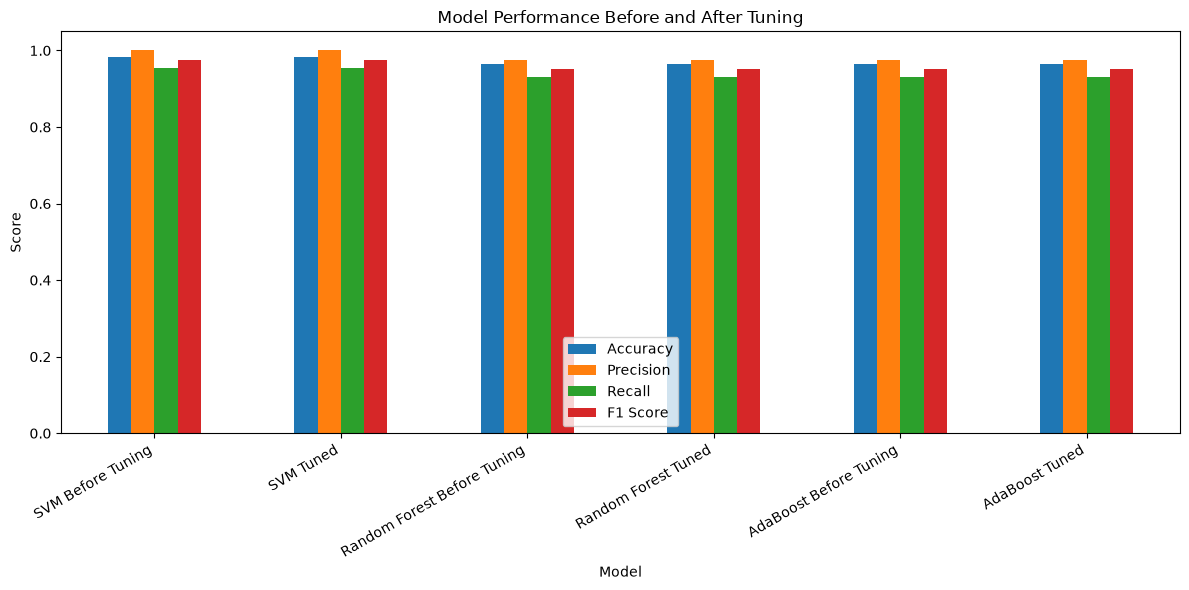

In [54]:
comparison.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    kind="bar", figsize=(12, 6)
)

plt.title("Model Performance Before and After Tuning")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha="right")
plt.legend()
plt.tight_layout()
plt.show()